In [9]:
from typing import Annotated, TypedDict

from langchain_core.messages import AIMessage, BaseMessage, HumanMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages

add_messages is a reducer function. Reducer needed because you need to append new messages, not replace previous ones. The imported function is more optimised for "BaseMessage" type, which is why we are using it over operator.add

In [5]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [3]:
llm = ChatOpenAI(
    base_url='http://127.0.0.1:9931/v1',
    model='local qwen3.5:4b',
    api_key='not needed'
)

In [6]:
def chat(state: ChatState):
    messages = state['messages']
    response = llm.invoke(messages)

    return {'messages': [response]}

In [12]:
from langgraph.checkpoint.memory import MemorySaver

checkpointer = MemorySaver()

In [13]:
graph = StateGraph(ChatState)

graph.add_node('chat', chat)

graph.add_edge(START, 'chat')
graph.add_edge('chat', END)

chatbot = graph.compile(checkpointer=checkpointer)

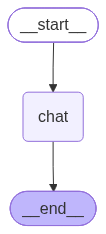

In [14]:
chatbot

In [10]:
initial_state = {
    'messages': [HumanMessage(content='HI, how are you?')]
}

output_state = chatbot.invoke(initial_state)

In [11]:
output_state

{'messages': [HumanMessage(content='HI, how are you?', additional_kwargs={}, response_metadata={}, id='19829276-cf9c-498f-9971-061393736902'),
  AIMessage(content="Hello! I'm doing well, thank you for asking. How about you? Is there anything you'd like to chat about or need help with today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 32, 'prompt_tokens': 18, 'total_tokens': 50, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': '../models/Qwen_Qwen3.5-4B-Q4_0.gguf', 'system_fingerprint': 'b11660-711780ffc', 'id': 'chatcmpl-ptFFQCnvE6jsmw1uVLK7GGwsmS058S6l', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a15318-1430-70c2-b905-2b9c4333df08-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 18, 'output_tokens': 32, 'total_tokens': 50, 'input